# Sales Variance Analysis Using Python



## 1. Introduction and Project Objective

Sales revenue can change because a company adjusts prices, sells different quantities, gains or loses customers, or sells a different combination of products. Comparing total revenue between two periods reveals the size of the change, but does not explain its components.

This project uses **sales variance analysis** to answer:

> How much of the change in revenue comes from price changes, and how much comes from changes in volume and sales mix?

The analysis compares corresponding periods in two years and separates the revenue change into a **Price Effect** and a **Volume/Mix Effect**. Python will be used to calculate and visualize these effects. Derivatives and integrals will then provide a mathematical interpretation of the standard approach.

Here, *variance* means a difference between periods, rather than the statistical measure of dispersion.



## 2. Scope and Business Classification

Calculations are performed for each **customer-site and product or product sub-family combination**. This matters because customers may pay different prices for the same product. A change in the proportion sold to each customer can alter the overall average price without any individual price changing.

The supplied methodology distinguishes three categories:

- **Base business:** established relationships with more than 12 months of business and comparable information for the periods analyzed.
- **New business (In):** newly started relationships, which remain in this category for a maximum of 11 rolling months under the supplied methodology.
- **Lost business (Out):** relationships confirmed to have ended.

Price effects are calculated for eligible base business. New and lost business contribute to Volume/Mix. Sales history or relationship dates are needed to establish eligibility; sales in both periods alone do not prove the required duration.



## 3. Revenue Model

For one customer–product relationship, sales revenue is:

$$
S = PV + F
$$

where:

- $S$ is sales revenue;
- $P$ is the variable selling price per unit;
- $V$ is the quantity sold;
- $F$ is the total contractual fixed charge for the reporting period.

If there is no fixed charge, $F=0$. When several transactions are combined, the average variable price is volume-weighted:

$$
P = \frac{\text{Total Variable Sales Revenue}}{\text{Total Quantity Sold}}
$$

Fixed charges are kept separate. Otherwise, a lower quantity could increase revenue per unit even when contractual prices have not changed.



## 4. Standard Price and Volume/Mix Decomposition

The decomposition explains the revenue change using two controlled comparisons. For one base-business relationship:

$$
S_1=P_1V_1+F_1,\qquad S_2=P_2V_2+F_2.
$$

Subscripts $1$ and $2$ mean the previous and current periods. Price, quantity, and fixed charges can all change. Comparing $S_1$ with $S_2$ directly tells us the total movement, but does not isolate these drivers.



### 4.1. Create an Intermediate Scenario

First calculate revenue with **current commercial terms and the previous quantity**:

$$
S^*=P_2V_1+F_2.
$$

This hypothetical scenario separates the comparison into two steps:

| Step | What changes? | What stays constant? | Business question |
|---|---|---|---|
| $S_1\rightarrow S^*$ | Variable price and fixed charge | Previous quantity $V_1$ | What would the new terms earn on the old quantity? |
| $S^*\rightarrow S_2$ | Quantity | Current price $P_2$ and charge $F_2$ | What does the quantity change contribute at the new price? |

This sequence follows the supplied methodology: prices are compared on previous-period quantities, and quantity changes are valued at current-period prices. It is a reporting convention, rather than a statement about which commercial change happened first.



### 4.2. Price Effect: Reprice the Original Business

Subtract previous revenue from the intermediate scenario:

$$
\begin{aligned}
\text{Price Effect}&=S^*-S_1\\
&=(P_2V_1+F_2)-(P_1V_1+F_1)\\
&=(P_2-P_1)V_1+(F_2-F_1).
\end{aligned}
$$

The first term measures the unit-price change applied to the original quantity; the second measures the change in the period's fixed charge. Holding quantity constant prevents additional units sold from inflating the pricing contribution.

Using the example in Section 5, the intermediate revenue is $11\times100+220=1{,}320$ euros. Compared with EUR 1,200 previously, this adds EUR 100 from variable price and EUR 20 from fixed charges: a EUR 120 price effect.



### 4.3. Volume/Mix Effect: Move to the Actual Quantity

Subtract the intermediate revenue from current revenue:

$$
\begin{aligned}
\text{Volume/Mix Effect}&=S_2-S^*\\
&=(P_2V_2+F_2)-(P_2V_1+F_2)\\
&=P_2(V_2-V_1).
\end{aligned}
$$

The fixed charge cancels because it is already at its current level. The additional 20 units in the example are valued at EUR 11 each, giving EUR 220. The two comparisons reconcile automatically:

$$
(S^*-S_1)+(S_2-S^*)=S_2-S_1
$$

$$
\boxed{\Delta S=\text{Price Effect}+\text{Volume/Mix Effect}}.
$$



### 4.4. Apply the Calculation Across the Business

Calculate the effects separately for each eligible base-business relationship $i\in B$, then sum:

$$
\text{Price Effect}=\sum_{i\in B}\left[(P_{2i}-P_{1i})V_{1i}+(F_{2i}-F_{1i})\right]
$$

$$
\text{Volume/Mix Effect}=\sum_{i\in B}P_{2i}(V_{2i}-V_{1i})
+\sum_{i\in I}S_{2i}-\sum_{i\in O}S_{1i}.
$$

Here, $I$ and $O$ denote new and lost business. Their contributions are full revenues, including any fixed charges: add current revenue from new business and subtract previous revenue from lost business. Do not invent missing comparison prices.

For a consistently classified dataset, total effects reconcile to the company-wide revenue change. Volume/Mix combines quantity changes, customer/product composition changes, and the price-volume interaction explained in Section 6. It does not separately measure pure mix.



### 4.5. Price-Volume Area Diagram

With **volume on the horizontal axis** and **variable price on the vertical axis**, rectangle area is revenue: units multiplied by euros per unit gives euros. The following diagram uses the example in Section 5, where both price and quantity increase.

- **Previous variable sales:** the blue rectangle has width $V_1=100$ and height $P_1=10$. Its area is $P_1V_1=1{,}000$ euros.
- **Variable price effect:** the teal strip above the blue rectangle has width $V_1$ and height $P_2-P_1$. Its area is $(P_2-P_1)V_1=(11-10)\times100=100$ euros. The sign is current minus previous, so an increase is positive.
- **Volume/Mix effect:** the orange strip to the right has width $V_2-V_1$ and the full current height $P_2$. Its area is $(V_2-V_1)P_2=(120-100)\times11=220$ euros.

The three areas fit together without overlap to form the current variable-sales rectangle: $P_2V_2=1{,}320$ euros. The hatched upper-right corner is the EUR 20 interaction, $(P_2-P_1)(V_2-V_1)$, already included in the orange strip. It must not be counted again as a price contribution.

**Fixed charges sit outside this geometry.** The full price effect adds the EUR 20 fixed-charge increase to the EUR 100 teal area, giving EUR 120. Adding fixed charges to the period revenues gives EUR 1,200 previously and EUR 1,540 currently, consistent with the revenue bridge below.

This diagram also previews the integrals in Section 6: $\int_{P_1}^{P_2}V_1\,dP$ measures the teal area, and $\int_{V_1}^{V_2}P_2\,dV$ measures the orange area. Only their integration direction differs; both results are revenue amounts.


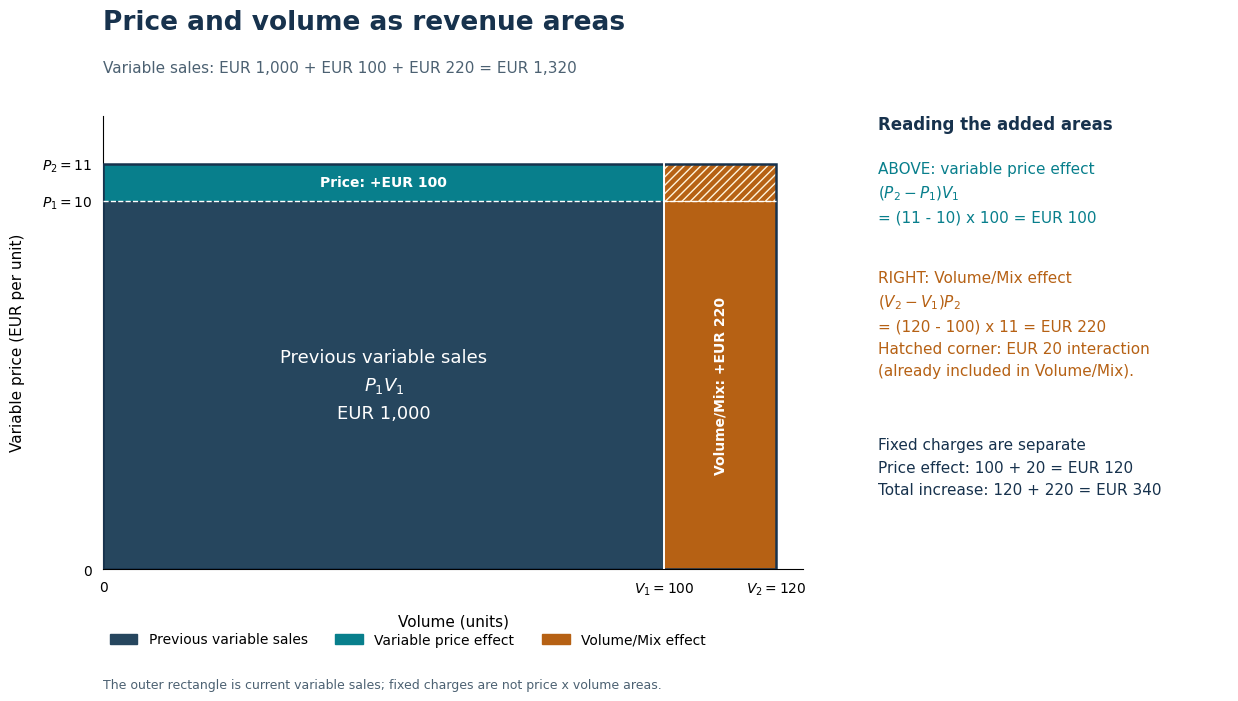

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

# Same customer-product example; rectangle areas exclude fixed charges.
p1, p2 = 10, 11
v1, v2 = 100, 120
f1, f2 = 200, 220
previous_variable_sales = p1 * v1
current_variable_sales = p2 * v2
variable_price_effect = (p2 - p1) * v1
volume_mix_effect = (v2 - v1) * p2
fixed_charge_effect = f2 - f1
interaction = (p2 - p1) * (v2 - v1)
assert current_variable_sales == previous_variable_sales + variable_price_effect + volume_mix_effect

fig = plt.figure(figsize=(12.5, 7.2), facecolor='white')
ax = fig.add_axes([0.08, 0.19, 0.56, 0.63])
notes = fig.add_axes([0.70, 0.19, 0.28, 0.63])
notes.axis('off')
blue, teal, orange = '#26465E', '#087F8C', '#B66114'

# Three non-overlapping rectangles tile the current variable-sales area.
ax.add_patch(Rectangle((0, 0), v1, p1, facecolor=blue, zorder=2))
ax.add_patch(Rectangle((0, p1), v1, p2 - p1, facecolor=teal, zorder=2))
ax.add_patch(Rectangle((v1, 0), v2 - v1, p2, facecolor=orange, zorder=2))
# The interaction remains part of Volume/Mix; hatching marks it, not a new effect.
ax.add_patch(Rectangle((v1, p1), v2 - v1, p2 - p1,
                       facecolor='none', edgecolor='#FFF4DC', hatch='////',
                       linewidth=0.8, zorder=3))
ax.add_patch(Rectangle((0, 0), v2, p2, facecolor='none',
                       edgecolor='#17324D', linewidth=1.8, zorder=4))
ax.plot([v1, v1], [0, p2], color='white', linewidth=1.4, zorder=4)
ax.plot([0, v2], [p1, p1], color='white', linestyle='--', linewidth=1, zorder=4)
ax.text(v1/2, p1/2,
        f'Previous variable sales\n$P_1 V_1$\nEUR {previous_variable_sales:,.0f}',
        ha='center', va='center', color='white', fontsize=13, linespacing=1.6)
ax.text(v1/2, (p1+p2)/2, f'Price: +EUR {variable_price_effect:,.0f}',
        ha='center', va='center', color='white', fontsize=10, fontweight='bold')
ax.text((v1+v2)/2, p1/2, f'Volume/Mix: +EUR {volume_mix_effect:,.0f}',
        ha='center', va='center', color='white', fontsize=10,
        fontweight='bold', rotation=90)
ax.set_xlim(0, v2*1.04)
ax.set_ylim(0, p2*1.12)
ax.set_xticks([0, v1, v2], ['0', f'$V_1={v1}$', f'$V_2={v2}$'])
ax.set_yticks([0, p1, p2], ['0', f'$P_1={p1}$', f'$P_2={p2}$'])
ax.set_xlabel('Volume (units)', fontsize=11, labelpad=12)
ax.set_ylabel('Variable price (EUR per unit)', fontsize=11, labelpad=12)
ax.tick_params(length=0, pad=8)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

notes.text(0, 1, 'Reading the added areas', fontsize=12,
           fontweight='bold', color='#17324D', va='top')
notes.text(0, 0.90,
           'ABOVE: variable price effect\n'
           r'$(P_2-P_1)V_1$' + '\n'
           f'= ({p2} - {p1}) x {v1} = EUR {variable_price_effect}',
           fontsize=11, color=teal, va='top', linespacing=1.6)
notes.text(0, 0.66,
           'RIGHT: Volume/Mix effect\n'
           r'$(V_2-V_1)P_2$' + '\n'
           f'= ({v2} - {v1}) x {p2} = EUR {volume_mix_effect}\n'
           f'Hatched corner: EUR {interaction} interaction\n'
           '(already included in Volume/Mix).',
           fontsize=11, color=orange, va='top', linespacing=1.6)
notes.text(0, 0.29,
           'Fixed charges are separate\n'
           f'Price effect: {variable_price_effect} + {fixed_charge_effect} = EUR {variable_price_effect + fixed_charge_effect}\n'
           f'Total increase: {variable_price_effect + fixed_charge_effect} + {volume_mix_effect} = EUR {variable_price_effect + fixed_charge_effect + volume_mix_effect}',
           fontsize=11, color='#17324D', va='top', linespacing=1.6)
fig.text(0.08, 0.94, 'Price and volume as revenue areas',
         fontsize=19, fontweight='bold', color='#17324D')
fig.text(0.08, 0.88,
         f'Variable sales: EUR {previous_variable_sales:,.0f} + '
         f'EUR {variable_price_effect:,.0f} + EUR {volume_mix_effect:,.0f}'
         f' = EUR {current_variable_sales:,.0f}',
         fontsize=11, color='#4C6172')
fig.legend(handles=[Patch(color=blue, label='Previous variable sales'),
                    Patch(color=teal, label='Variable price effect'),
                    Patch(color=orange, label='Volume/Mix effect')],
           loc='lower left', bbox_to_anchor=(0.075, 0.065),
           ncol=3, frameon=False, fontsize=10)
fig.text(0.08, 0.025,
         'The outer rectangle is current variable sales; fixed charges are not price x volume areas.',
         fontsize=9, color='#4C6172')
plt.show()


## 5. Worked Example

Consider an established customer site buying the same product in both periods. Its contract contains a variable price per unit and a fixed service charge:

| Measure | Previous period | Current period |
|---|---:|---:|
| Quantity sold | 100 | 120 |
| Variable price per unit | €10 | €11 |
| Total fixed charge | €200 | €220 |
| Sales revenue | €1,200 | €1,540 |

Previous-period revenue is $10\times100+200=1{,}200$ euros. Current-period revenue is $11\times120+220=1{,}540$ euros. The observed change is therefore:

$$
\Delta S=1{,}540-1{,}200=340\text{ euros}
$$



### Step 1: Reprice the Previous Quantity

First ask: **What would revenue have been if the customer had bought the previous quantity under the current prices and fixed charge?**

This creates an intermediate scenario:

$$
S^*=P_2V_1+F_2=11\times100+220=1{,}320\text{ euros}
$$

Compared with the original EUR 1,200, this scenario adds EUR 100 from the EUR 1 per-unit price increase and EUR 20 from the higher fixed charge. Thus:

$$
(11-10)\times100+(220-200)=120\text{ euros}
$$

$$
\text{Price Effect}=S^*-S_1=1{,}320-1{,}200=120\text{ euros}
$$

Using the previous quantity isolates the pricing contribution from the customer's decision to purchase more units.



### Step 2: Move to the Actual Current Quantity

Next ask: **How much additional revenue comes from moving from 100 to 120 units at the current price?**

The additional 20 units generate EUR 11 each. The fixed charge is already at its current level, so it does not change in this step:

$$
11\times(120-100)=220\text{ euros}
$$

The complete bridge is:

| Scenario | Price per unit | Quantity | Fixed charge | Revenue | Change |
|---|---:|---:|---:|---:|---:|
| Previous period | EUR 10 | 100 | EUR 200 | EUR 1,200 | — |
| Previous quantity, current commercial terms | EUR 11 | 100 | EUR 220 | EUR 1,320 | +EUR 120 price effect |
| Current period | EUR 11 | 120 | EUR 220 | EUR 1,540 | +EUR 220 Volume/Mix |

The EUR 340 increase is fully explained: $120+220=340$. In this single-product example, Volume/Mix comes from quantity growth, including its interaction with price. Across many customer–product relationships, the same calculation also captures changes in sales composition.

This is a revenue explanation. The EUR 220 attributed to quantity growth is additional revenue; its profit contribution depends on the costs of supplying those units.



## 6. How Derivatives and Integrals Explain the Methodology

Section 4 gives the exact algebraic calculation. Calculus explains it in two stages: **derivatives identify revenue sensitivity; integrals accumulate that sensitivity over a specified change**. The methodology chooses what is held constant, so it also determines which sensitivities enter each integral.



### 6.1. Derivatives: Identify the Sensitivity

For one relationship, revenue is the function $S(P,V,F)=PV+F$. A partial derivative changes one input while holding the others fixed. For example, increase price by a small amount $h$ while keeping quantity and fixed charge unchanged:

$$
\frac{S(P+h,V,F)-S(P,V,F)}{h}
=\frac{(P+h)V+F-(PV+F)}{h}=V.
$$

Taking the limit as $h$ tends to zero gives $\partial S/\partial P=V$. The business meaning is that the quantity being repriced determines revenue sensitivity to price. The three sensitivities are:

$$
\frac{\partial S}{\partial P}=V,\qquad
\frac{\partial S}{\partial V}=P,\qquad
\frac{\partial S}{\partial F}=1.
$$

| Derivative | Meaning, with other inputs fixed | Application |
|---|---|---|
| $\partial S/\partial P=V$ | Revenue change per unit of price change | At 100 units, a EUR 0.10 per-unit price increase adds EUR 10 |
| $\partial S/\partial V=P$ | Revenue change per additional unit | At EUR 11 per unit, 2 more units add EUR 22 |
| $\partial S/\partial F=1$ | Revenue change per euro of fixed-charge change | A EUR 20 charge increase adds EUR 20 |

The units are consistent: units sold multiplied by euros per unit gives euros of revenue. These sensitivities measure revenue, not profit. Holding quantity fixed also means the price derivative does not predict customer demand after a price increase; that requires a demand model.

Together, the derivatives give the total differential:

$$
dS=V\,dP+P\,dV+dF.
$$

The symbol $d$ describes infinitesimal changes; $\Delta$ describes finite changes between periods. Using the starting sensitivities for an entire finite change can miss the interaction between price and quantity, as shown in Section 6.4.

